# 01 — Counts, rules, Wilson intervals and repeated tests
**Practical 1: who loses access to an online Analyst assessment?** Slides 9–38. The second notebook investigates the mechanism behind the same 40 records.

The scenario has 20 women and 20 men, all with complete applications, all meeting a stated skill cutoff of 70. There are 40 assessment seats. Original decisions invite 8 women and 16 men. An invitation is access to the next assessment, not a job offer.

These are constructed teaching records, not observations about any real population. The group labels simplify arithmetic and are not a comprehensive identity taxonomy.

**Part 1** is a complete worked lesson: load data, count, search five small contexts, calculate Wilson bounds and understand false alarms. **Part 2** supplies project questions and runnable TODO scaffolds.

## Part 1 — A complete lesson
### 1. Load and inspect the record schema

In [1]:
from pathlib import Path  # Locate the extracted practical pack.
import sys  # Make the small teaching helper module importable.
import numpy as np  # Calculate probabilities and reproducible simulations.
import pandas as pd  # Load and inspect the actual row-level data.
import matplotlib.pyplot as plt  # Draw figures from computed values.
from scipy.stats import norm, fisher_exact  # Use documented reference distributions and tests.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/audit.py').exists())  # Find the pack from its root or notebooks folder.
sys.path.insert(0, str(root / 'src'))  # Import helpers from this pack, not an unrelated installation.
from audit import wilson, report, rule_metrics, search_contexts, family_false_alarm  # Load inspectable functions.
from prepare_data import prepare  # Reproduce the constructed raw and processed data.
applicants = prepare(root)  # Generate the same deterministic 40-person cohort.
plt.rcParams.update({'font.size': 12, 'figure.dpi': 130})  # Keep notebook figures legible.
print(root, '\nRecords:', len(applicants))  # Verify the active dataset location and size.

/workspace/scratch/a78d3bf087d5/build/discovery-simple/practical 
Records: 40


In [2]:
print(applicants[['record_id', 'group', 'skill_score', 'certificate', 'experience_years', 'invited', 'denied']].head(8).to_string(index=False))  # Inspect actual records before calculating metrics.
assert applicants.record_id.is_unique  # Count each application once.
assert len(applicants) == 40 and applicants.application_complete.eq(1).all()  # Verify the declared full population.
print(report(applicants).to_string(index=False))  # Display both numerators and denominators.

record_id group  skill_score  certificate  experience_years  invited  denied
      W01 Women           77            0                 1        0       1
      W02 Women           84            0                 2        0       1
      W03 Women           91            0                 1        0       1
      W04 Women           98            0                 2        0       1
      W05 Women           74            0                 1        1       0
      W06 Women           81            0                 3        0       1
      W07 Women           88            0                 4        0       1
      W08 Women           95            0                 5        0       1
group  events  total  rate
Women      12     20   0.6
  Men       4     20   0.2


### 2. Recompute the small example by hand
Women: 12 denied out of 20, so the adverse rate is .60. Men: 4/20=.20. The whole context has 16/40=.40 denied.

For the rule **Women AND Analyst → denied**:

\[\mathrm{support}=12/40=.30,\qquad \mathrm{confidence}=12/20=.60.\]
\[\mathrm{elift}=(12/20)/(16/40)=1.50.\]
\[\mathrm{risk\ difference}=.60-.20=.40,\qquad \mathrm{risk\ ratio}=.60/.20=3.\]

Extended lift compares with a baseline that includes the audited group. The risk ratio uses the other group. The favorable invitation-rate ratio is .40/.80=.50. Keep the outcome direction explicit.

There is no trained classifier here. We audit an allocation rule and its recorded decisions.

support: 0.3000
confidence: 0.6000
extended_lift: 1.5000
gap: 0.4000
risk_ratio: 3.0000
favorable_ratio: 0.5000


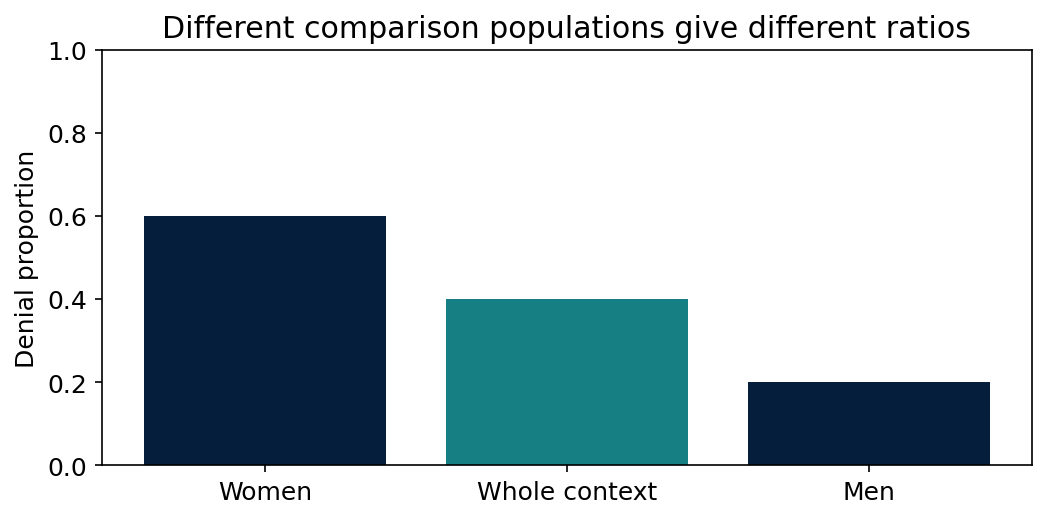

In [3]:
base = rule_metrics(applicants)  # Calculate all metrics on the complete 40-person table.
for name in ['support', 'confidence', 'extended_lift', 'gap', 'risk_ratio', 'favorable_ratio']:  # Select the six quantities taught on the slides.
    print(f'{name}: {base[name]:.4f}')  # Display enough precision to check the arithmetic.
assert np.isclose(base['extended_lift'], 1.5) and np.isclose(base['gap'], .4)  # Check the key worked result.
fig, ax = plt.subplots(figsize=(8, 3.6))  # Create a simple rate comparison.
ax.bar(['Women', 'Whole context', 'Men'], [.6, .4, .2], color=['#041E3C', '#157F83', '#041E3C'])  # Plot the three distinct denominators.
ax.set(ylim=(0, 1), ylabel='Denial proportion', title='Different comparison populations give different ratios')  # Label the outcome and scale.
plt.show()  # Save and display the computed figure.

### 3. A bounded search that students can inspect
The declared family is five contexts: all applicants, certificate=0, certificate=1, experience under 3, and experience 3+. Each context must contain at least five women and five men. We use **λ=1.25** for an extended-lift review flag.

The contexts overlap. Their results are not independent tests. A top-ranked context is exploratory, not an independently confirmed finding. Certificate is optional in the stated scenario, so conditioning on it does not establish that excluding people without it is justified.

For certificate=0, women have 7/10 denied and men 2/10. The mixed context rate is 9/20=.45, lift .70/.45≈1.556, gap .50, support 7/40=.175.

In [4]:
rules = search_contexts(applicants, min_per_group=5, review_ratio=1.25)  # Enumerate only the declared small context family.
cols = ['context_name', 'women_denied', 'women_n', 'men_denied', 'men_n', 'gap', 'extended_lift', 'review_flag']  # Keep counts beside scores.
print(rules[cols].to_string(index=False))  # Report all five contexts, not just the largest gap.
rules.to_json(root / 'data/processed/context_rules.json', orient='records', indent=2)  # Save a machine-readable audit result.
assert len(rules) == 5  # Verify the declared search family.

          context_name  women_denied  women_n  men_denied  men_n  gap  extended_lift  review_flag
        All applicants            12       20           4     20  0.4       1.500000         True
         certificate=0             7       10           2     10  0.5       1.555556         True
         certificate=1             5       10           2     10  0.3       1.428571         True
experience_band=Under3             7       10           2     10  0.5       1.555556         True
 experience_band=3plus             5       10           2     10  0.3       1.428571         True


### 4. Percentage, percentile and confidence level
**Percentage:** 12/20×100=60% is an observed rate.

**Percentile:** the 97.5th percentile of the **standard normal reference distribution** is approximately 1.96. It is a location on a distribution, not a percentile rank of applicants.

**Confidence level:** 95% is the nominal long-run coverage target of an interval procedure. A fixed true process rate does not acquire a 95% posterior probability merely because we computed one frequentist interval.

For a two-sided 95% interval, α=.05. Split the excluded .05 into .025 in each tail. The upper reference quantile is Φ⁻¹(.975)≈1.96. The Wilson interval uses this score-test reference. It is **not** an empirical bootstrap-percentile interval.

alpha=0.050, each tail=0.025, upper percentile=0.975, z=1.959964


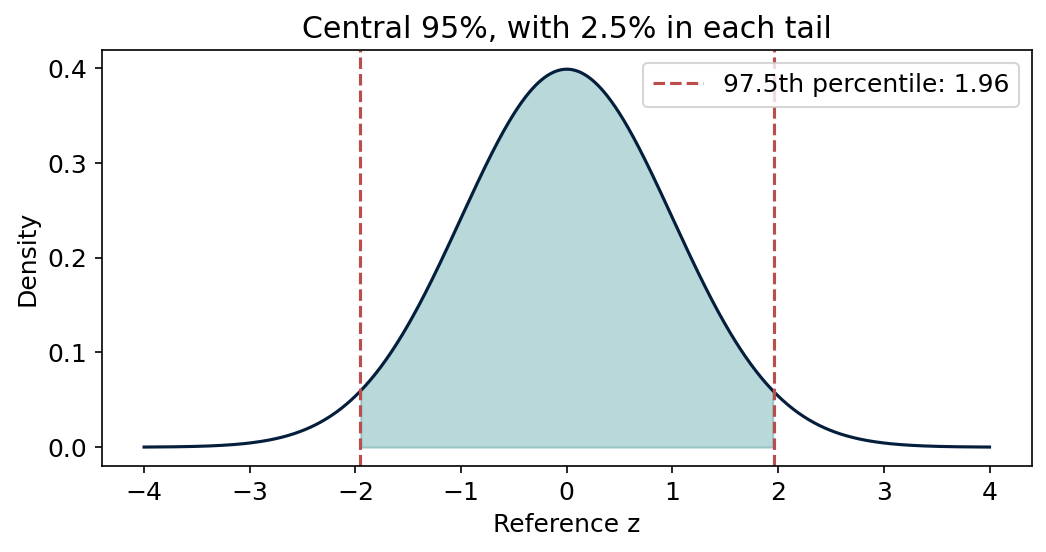

In [5]:
level = .95  # Choose the confidence level before inspecting desirable bounds.
alpha = 1 - level  # Allocate the remaining probability to the two reference tails.
z = norm.ppf(1 - alpha / 2)  # Find the 97.5th standard normal percentile.
print(f'alpha={alpha:.3f}, each tail={alpha/2:.3f}, upper percentile={1-alpha/2:.3f}, z={z:.6f}')  # Trace every reference quantity.
xx = np.linspace(-4, 4, 801)  # Define numeric z-coordinates for the reference density.
fig, ax = plt.subplots(figsize=(8, 3.6))  # Create a distribution figure.
ax.plot(xx, norm.pdf(xx), color='#041E3C')  # Draw the standard normal density.
ax.fill_between(xx, norm.pdf(xx), where=np.abs(xx) <= z, color='#157F83', alpha=.3)  # Mark the central reference area.
ax.axvline(z, color='#BA4E4A', linestyle='--', label=f'97.5th percentile: {z:.2f}')  # Show the upper critical location.
ax.axvline(-z, color='#BA4E4A', linestyle='--')  # Show the symmetric lower critical location.
ax.set(xlabel='Reference z', ylabel='Density', title='Central 95%, with 2.5% in each tail')  # Name the distribution, not the applicant outcome.
ax.legend()  # Label the critical quantile directly.
plt.show()  # Display the figure.

### 5. Wilson calculation, step by step
For an event count x and total n, let p̂=x/n and D=1+z²/n. Compute:

\[c=\frac{\hat p+z^2/(2 n)}{D},\qquad h=\frac{z\sqrt{\hat p(1-\hat p)/n+z^2/(4 n^2)}}{D}.\]
\[\mathrm{interval}=[c-h,c+h].\]

With x=12,n=20,z≈1.96, D≈1.1921, c≈.5839 and h≈.1973. The bounds are approximately [.3866,.7812]. The adjusted center is not exactly the observed .60.

The constructed dataset is not an empirical random sample. The interval here **illustrates a binomial sampling model**. For a population claim, justify independent comparable Bernoulli observations, the sampling process and a stable target probability. If all 20 women are a census of a fixed cohort, their cohort rate is known exactly; the interval would concern a wider process, not uncertainty about that observed count.

level           0.950000
x              12.000000
n              20.000000
phat            0.600000
z               1.959964
denominator     1.192073
center          0.583887
half_width      0.197306
lower           0.386582
upper           0.781193


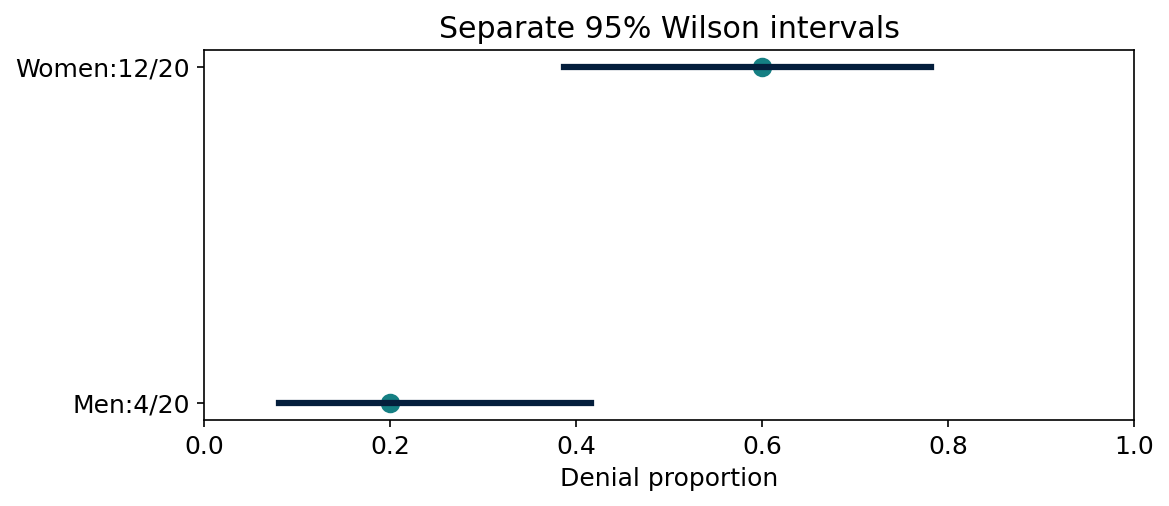

In [6]:
women_ci = wilson(12, 20, level=.95)  # Apply the explicit Wilson recipe to the worked count.
print(pd.Series(women_ci).to_string())  # Show the denominator, adjusted center, half-width and limits.
men_ci = wilson(4, 20, level=.95)  # Use the other group's own numerator and denominator.
assert np.isclose(women_ci['lower'], .3865815007622531)  # Check the displayed numerical result.
interval_rows = pd.DataFrame([{'group': 'Women', **women_ci}, {'group': 'Men', **men_ci}])  # Keep separate rate intervals separate.
interval_rows.to_csv(root / 'data/processed/wilson_group_intervals.csv', index=False)  # Save values behind the slide figure.
fig, ax = plt.subplots(figsize=(8, 3.2))  # Create an interval comparison.
for pos, row in enumerate([women_ci, men_ci]):  # Draw each group's interval from its own count.
    ax.plot([row['lower'], row['upper']], [1-pos, 1-pos], color='#041E3C', linewidth=3)  # Draw computed endpoints.
    ax.scatter([row['phat']], [1-pos], color='#157F83', s=70)  # Mark the observed proportion.
ax.set(yticks=[1, 0], yticklabels=['Women:12/20', 'Men:4/20'], xlim=(0, 1), xlabel='Denial proportion', title='Separate 95% Wilson intervals')  # Show counts and the probability scale.
plt.show()  # Display the comparison.

### 6. Interpretation and sensible applications
Under repeated comparable sampling, the Wilson method aims at approximately the chosen coverage. Binomial counts are discrete, so actual coverage is not exactly 95% for every n and true probability.

The interval does not contain “95% of the applicants.” It is not a probability of unlawful discrimination. Two separate rate intervals are not a direct interval or test for their difference; do not decide whether the gap exists by checking overlap alone.

At the same 12/20 count, higher confidence makes the interval wider. At the same observed 60% rate, a larger independent sample usually narrows it. More data do not repair an unrepresentative sample, duplicated records or a biased measurement.

In [7]:
levels = pd.DataFrame([wilson(12, 20, level=l) for l in [.90, .95, .99]])  # Hold the data fixed while changing confidence level.
sizes = pd.DataFrame([wilson(12, 20), wilson(120, 200)])  # Hold the observed rate fixed while changing sample size.
print(levels[['level', 'z', 'lower', 'upper']].to_string(index=False))  # Show how reference percentiles affect bounds.
print(sizes[['x', 'n', 'phat', 'lower', 'upper']].to_string(index=False))  # Show narrower uncertainty for the hypothetical larger sample.

 level        z    lower    upper
  0.90 1.644854 0.418556 0.757613
  0.95 1.959964 0.386582 0.781193
  0.99 2.575829 0.329313 0.820865
  x   n  phat    lower    upper
 12  20   0.6 0.386582 0.781193
120 200   0.6 0.530837 0.665394


### 7. A true null, a test level and a rare fair-lottery result
This is a **separate statistics example**, not the car-filter cohort. A department invites each applicant using a 50% random lottery that ignores group. H₀ says the two group invitation probabilities are equal. Here H₀ is true by construction.

A possible realization gives women 8 denials and 2 invitations, men 2 denials and 8 invitations. A two-sided Fisher test on the shown table gives p≈.0230. At a predeclared .05 threshold it flags, even though the generating lottery is fair. This is an intentionally chosen rare illustration, not a claim that every lottery produces this table.

A valid level-.05 test has false-alarm probability **at most** .05 under its null. Fisher tests are discrete and often conservative. A p-value is not the probability that H₀ is true, nor the probability that discrimination occurred.

In [8]:
lottery_table = np.array([[8, 2], [2, 8]])  # Rows are groups; columns are denied and invited.
p_value = fisher_exact(lottery_table, alternative='two-sided').pvalue  # Use the declared two-sided conditional Fisher definition.
print('Two-sided Fisher p:', p_value, 'Flag at .05:', p_value <= .05)  # Separate a statistical flag from the known fair mechanism.
print('Adjusted p for 20 tests:', min(1, 20*p_value))  # Illustrate a family adjustment using the complete family size.

Two-sided Fisher p: 0.023014137565221155 Flag at .05: True
Adjusted p for 20 tests: 0.4602827513044231


### 8. Independent true-null tests: why the family risk grows
For an easy probability calculation, assume all m nulls are true, the tests are independent, and **each test has actual false-alarm probability exactly α**. Then:

\[P(\text{no false alarms})=(1-\alpha)^m,\qquad P(\text{at least one})=1-(1-\alpha)^m.\]

For α=.05: two tests give 1−.95²=.0975; twenty give 1−.95²⁰≈.6415. The .6415 is a family event probability, not a probability that one particular finding is false.

The exact-size and independence assumptions are not established for our five overlapping context rules. If tests have actual size below .05, the formula at α=.05 is an upper bound under independence. Dependence requires other reasoning. Do not claim that a Fisher-test pipeline has exactly the illustrated .6415 risk.

 tests  family_false_alarm
     1            0.050000
     2            0.097500
    10            0.401263
    20            0.641514
   100            0.994079


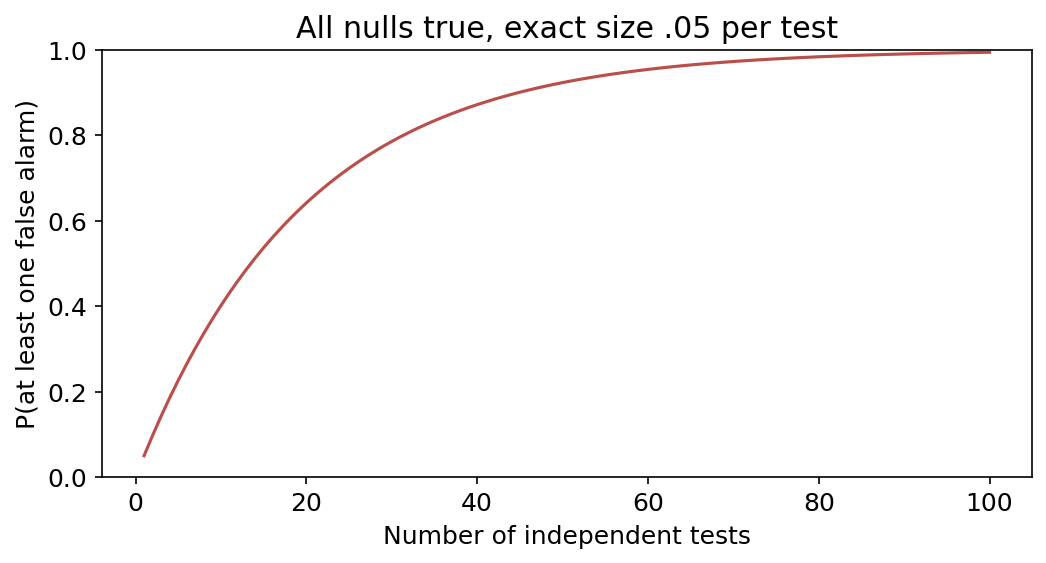

In [9]:
m_grid = np.array([1, 2, 10, 20, 100])  # Use the family sizes displayed on the slides.
family_table = pd.DataFrame({'tests': m_grid, 'family_false_alarm': family_false_alarm(m_grid, .05)})  # Apply the stated mathematical model.
print(family_table.to_string(index=False))  # Report probabilities, not simulated empirical facts.
family_table.to_csv(root / 'data/processed/independent_true_null_model.csv', index=False)  # Save the source values for the teaching chart.
fig, ax = plt.subplots(figsize=(8, 3.7))  # Draw numeric test counts on the horizontal axis.
mm = np.arange(1, 101)  # Calculate the full curve across one to one hundred tests.
ax.plot(mm, family_false_alarm(mm, .05), color='#BA4E4A')  # Show increasing opportunities for a false alarm.
ax.set(xlabel='Number of independent tests', ylabel='P(at least one false alarm)', ylim=(0, 1), title='All nulls true, exact size .05 per test')  # Put assumptions in the figure title.
plt.show()  # Display the family-risk curve.

### 9. Check the ideal model with a simulation
We simulate independent standard-normal test statistics under a zero-effect null, then turn them into two-sided p-values. This is a calibrated continuous test model, not the actual hiring data and not Fisher's discrete test. Repeating many twenty-test families should yield a false-family frequency close to .6415, with Monte Carlo variation.

In [10]:
rng = np.random.default_rng(42)  # Fix the simulation seed for reproducibility.
null_z = rng.standard_normal((20000, 20))  # Generate independent zero-effect test statistics in each family.
null_p = 2*norm.sf(np.abs(null_z))  # Calculate exact continuous-model two-sided null p-values.
empirical_family_risk = np.any(null_p <= .05, axis=1).mean()  # Count families with at least one false flag.
print('Simulation:', empirical_family_risk, 'Theory:', family_false_alarm(20, .05))  # Compare a simulation frequency with its theoretical target.
bonferroni_family_risk = np.any(null_p <= .05/20, axis=1).mean()  # Apply a family-wide .05 Bonferroni policy.
print('With Bonferroni:', bonferroni_family_risk)  # Observe approximate family control without promising exact .05.

Simulation: 0.64355 Theory: 0.6415140775914581
With Bonferroni: 0.05135


### 10. Apply the idea responsibly
Predeclare the question family and comparison. Report all counts and attempted contexts. Bonferroni uses α/m per test, or adjusted p=min(1,m×p). With valid p-values it controls family false alarms even when tests depend, though it can be conservative.

Exploration can suggest a question. Freeze that question and evaluate it on fresh suitable records before treating it as independent confirmation. A non-significant result does not certify an ethical process. A known unnecessary exclusion still merits review.

**Classroom output:** one count table, one explained subgroup row, the complete five-context results, one Wilson calculation and a paragraph distinguishing a false-family probability from a probability of discrimination.

# Part 2 — Guided final-project extensions
Choose one substantive extension. State the target population, outcome and assumptions; keep a log of attempted analyses; preserve a genuinely fresh follow-up set if you claim confirmation. Submit an executed notebook, raw/processed lineage, result tables and a short ethical decision memo.

## TODO A — Sample size and interval coverage
Use a known binomial rate such as .60. Repeatedly draw independent samples at n=10,20,50,200. Compute Wilson bounds and the fraction covering the fixed true rate. Plot average width and coverage. Explain why one experiment need not contain exactly 95% covering intervals and why selected samples can invalidate the intended interpretation.

In [11]:
project_config = {'true_rate': .60, 'sample_sizes': [10, 20, 50, 200], 'repetitions': 5000, 'seed': 101}  # Declare a study before running it.
print(project_config)  # TODO: generate binomial counts, calculate coverage and plot the results.

{'true_rate': 0.6, 'sample_sizes': [10, 20, 50, 200], 'repetitions': 5000, 'seed': 101}


## TODO B — The search family and dependency
Extend context depth from one to two and min support from five to three or ten. Preserve all results and list which records contexts share. Compare an exploratory top gap with a frozen question on a genuinely new synthetic cohort. Do not apply the independent-test formula to overlapping rules.

## TODO C — Exact-size versus discrete tests
For fixed row totals 10 and 10 and total denials 10, enumerate possible 2×2 tables. Use `scipy.stats.hypergeom` for null probabilities and `fisher_exact` for p-values. Sum null probabilities of tables with p≤.05. Compare the actual conditional size with .05, then explain how it affects the twenty-test formula. This is optional statistical self-study, not required for the core lab.

## TODO D — Ethical interpretation and independent work
Explain why a numerical threshold cannot validate a feature or identify intent. In an oral check, recompute one denominator, explain the 97.5th percentile, and state one independence assumption. Cite external and AI-assisted contributions. The next notebook investigates the known car-feature mechanism in the same cohort.

**Readings:** NIST Wilson intervals; Public Health Data Science Appendix 3; the ASA p-value statement; the NIST multiple-comparisons material. Full links are in `SOURCES.md`.